# Week 2 · Lists, tuples and dictionaries

**CM3801 · CMT309/509 · CMT124** · shared session · Thursday 15 October 2026

Last week every value was a single number or a single string. Today your programs start holding **many values at once**: a week of temperatures, a pair of coordinates, a city → population lookup.

By the end of today you can create, index and slice **tuples** and **lists**, explain **mutability** (and why `b = a` can surprise you), change lists with methods, and build and query **dictionaries**.

Today has three teaching parts and a lab: **Hour 1** tuples and lists · **Hour 2** mutability and list methods · **Hour 3** dictionaries · **Lab** a week of Cardiff weather.

## Hour 1 · Sequences: tuples and lists

### A string is already a sequence

Last week you indexed and sliced strings. A string is a **sequence**: its items sit in a fixed order, and each has a position. Python has two more general sequences whose items can be of **any** type:

| Type | Written with | Example | Can it change? |
|---|---|---|---|
| **tuple** | commas (brackets optional, but clearer) | `("one", "two", 3)` | no (immutable) |
| **list** | square brackets `[ ]` (required) | `["one", "two", 3]` | yes (mutable) |

A **dictionary** is a related collection, but not a sequence: you look items up by **key**, not by position. That is Hour 3.

Everything you know from strings carries over:

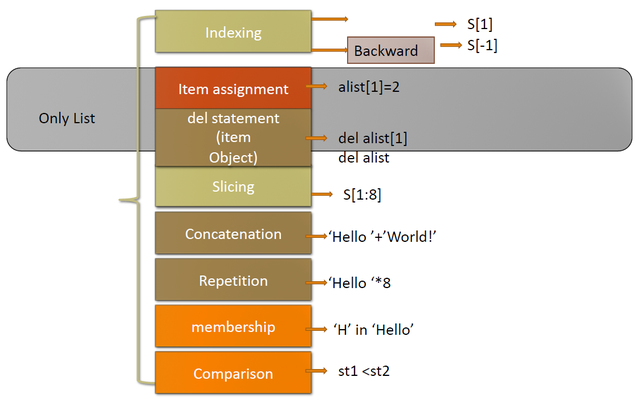

**Quick check:** with `st = "Cardiff Bay"`, what does `st[-3:]` give? (Week 1 slicing.)

<details><summary>Answer</summary>

`'Bay'`: the last three characters.

</details>

### Tuples: packing and unpacking

A tuple is created with **commas**. Putting several values into one tuple is called **packing**; taking them out into separate names is **unpacking**.

| Packing | Unpacking |
|---|---|
| 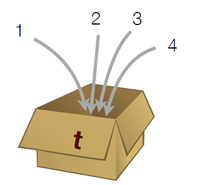 | 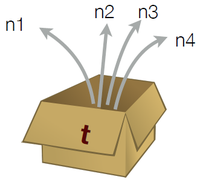 |

In [ ]:
# ✍️ Type along: pack the coordinates of Cardiff into a tuple, then unpack them

<details><summary>Code from class</summary>

```python
cardiff = 51.48, -3.18          # packing: the commas make the tuple
print(cardiff, type(cardiff))

lat, lon = cardiff              # unpacking: one name per item
print("latitude", lat, "longitude", lon)

t = 1, 2, 3, 4
n1, n2, n3, n4 = t
```

</details>

Unpacking needs **exactly** one name per item: `lat, lon = 1, 2, 3` is a `ValueError`.

**Predict:** brackets on their own don't make a tuple. What do `type((12))` and `type((12,))` return?

In [ ]:
print(type((12)))
print(type((12,)))
print(type(()), type(tuple("Hi")))

`(12)` is just the number 12 in brackets, like `(2 + 3)`. The **comma** makes the tuple: `(12,)` or even `12,`. `()` is an empty tuple, and `tuple("Hi")` turns a string into `('H', 'i')`.

### Lists

A list is created with **square brackets**, which are required. Items can be of any type, including other lists.

In [ ]:
empty = []
temps = [14.5, 16.0, 12.5, 18.5]
mixed = ["Cardiff", 362400, True, None]
print(type(empty), len(temps), mixed)
print(list("Hello"), list(range(5)))

### Indexing and slicing work the same way

Tuples and lists index **from 0**, count backwards with negatives, and slice with `[start:end:step]`, exactly like strings.

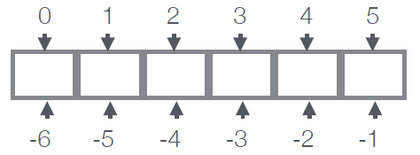

**Your turn:** use slicing to extract the letters `'w', 'a', 'y'` from **both** of these. Try a different style each time (positive indices for one, negative for the other).

In [ ]:
t1 = [1, 2, 'w', 'a', 'y', 9, 10]
t2 = 1, 3, 7, 2, 3, 'w', 'a', 'y'
# your code here

<details><summary>Answer</summary>

```python
t1[2:5]     # ['w', 'a', 'y']   a slice of a list is a list
t2[-3:]     # ('w', 'a', 'y')   a slice of a tuple is a tuple
```

</details>

### Nested lists: a table in a list

A list can hold lists. That is a simple way to store a table or a matrix:

$$
\begin{bmatrix} 1 & 2 & 3 & 4\\ 5 & 6 & 7 & 8\\ 9 & 10 & 11 & 12 \end{bmatrix}
\quad\Longleftrightarrow\quad
\texttt{t = [[1, 2, 3, 4], [5, 6, 7, 8], [9, 10, 11, 12]]}
$$

**Quick check:** what is `len(t)`? And which expression gives the integer `8`?

In [ ]:
t = [[1, 2, 3, 4], [5, 6, 7, 8], [9, 10, 11, 12]]
print(len(t))
print(t[1])
print(t[1][3])

`len(t)` is **3**: `t` holds three items, each a list. `t[1]` gives the row `[5, 6, 7, 8]`, and `t[1][3]` indexes into that row. Read double brackets from left to right.

**Try it:** change the cell to print the `11`, then the whole last row using a negative index.

### Takeaways: sequences

* Tuples and lists are **sequences**: indexing, slicing, `in`, `+`, `*` and `len()` all work as they do on strings.
* The **comma** makes a tuple (`12,`); square brackets make a list.
* Unpacking gives each item its own name: `lat, lon = cardiff`.
* Nested lists store tables; `t[row][column]` reads one value.

## Hour 2 · Mutability and list methods

### Mutable and immutable

* Objects whose value **can** change are **mutable**.
* Objects whose value **cannot** change are **immutable**.

Numbers are immutable. When you write `a = 20` after `a = 10`, the `10` is not changed: `a` is simply re-bound to a different object (Week 1's dynamic typing).

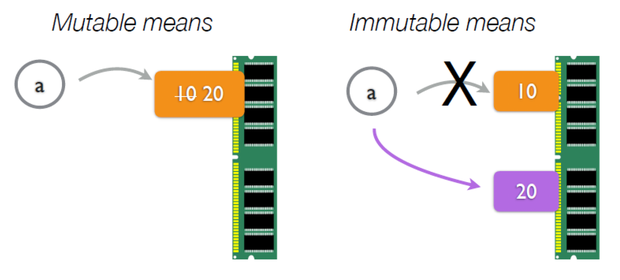

Strings and tuples are immutable too: they don't support **item assignment**.

**Before we run this:** the next two cells try to change one item of a string and of a tuple. What will Python say?

In [ ]:
# ⚠️ This cell raises an error on purpose
st = "random text"
st[0] = "R"

In [ ]:
# ⚠️ This cell raises an error on purpose
tp = (1, 2, 3)
tp[2] = 6

Both raise `TypeError: ... does not support item assignment`. To "change" a string you build a new one, for example `"R" + st[1:]`.

Lists are mutable: item assignment works at any level of nesting.

In [ ]:
a = [[1, 2, 3], "middle", [98, 99, 100]]
a[0][0] = 0          # change one item inside the inner list
a[1] = "centre"      # replace a whole item
print(a)

**Discuss:** this tuple contains a list. Tuples are immutable, so should the next cell fail?

In [ ]:
a = ([1, 2, 3], "two", "three")
a[0][0] = "one"
print(a)

It works. The tuple still holds **the same three objects**; we changed the *inside* of one of them, the list. `a[0] = [2, 3, 4]` would fail, because that tries to replace an item of the tuple.

### Aliasing: two names, one list

**Before we run this:** what will the two `print` lines show?

In [ ]:
x = [1, 2, 3]
y = x
x[0] = 100
print(x)
print(y)

`y` shows `[100, 2, 3]` too. `y = x` does **not** copy the list: it gives the same list a second name (an **alias**). Compare Week 1, where `z = x` and then `x = "BLUE"` left `z` alone: re-binding a name moves only that name, but *changing* a mutable object is seen through every name.

To get an independent copy, use `x[:]` or `x.copy()`. `is` asks "are these the same object?":

In [ ]:
# ✍️ Type along: alias vs copy, checked with `is`
x = [1, 2, 3]

<details><summary>Code from class</summary>

```python
x = [1, 2, 3]
y = x            # alias: same object
z = x.copy()     # copy: a new object (x[:] does the same)
x.append(4)
print(y, y is x)     # [1, 2, 3, 4] True
print(z, z is x)     # [1, 2, 3] False
```

</details>

### Building new lists: `+`, `*` and `del`

`+` joins two lists and `*` repeats one. Both create a **new** list. `del` removes items from a list (but not from a tuple).

In [ ]:
a = [1, 2, 3]
b = [10, 20, 30]
print(a + b, [1, "z"] * 3)
nums = list(range(10))
del nums[-4:]
print(nums)

### List methods

Methods change a list **in place** (the list itself changes; most of them return `None`):

| Method | Does |
|---|---|
| `append(x)` | add `x` to the end |
| `extend(seq)` | add every item of `seq` to the end |
| `insert(i, x)` | insert `x` at position `i` |
| `remove(x)` | remove the first item equal to `x` |
| `pop(i)` | remove the item at position `i` (default: the last) **and return it** |
| `sort()` / `reverse()` | sort / reverse the items in place |
| `index(x)` / `count(x)` | position of the first `x` / how many times `x` occurs |

The built-in **function** `sorted(seq)` is different from the **method** `.sort()`: it returns a **new**, sorted list and leaves the original alone.

In [ ]:
# ✍️ Type along: a shopping list that changes
basket = ["bread", "milk", "tea"]

<details><summary>Code from class</summary>

```python
basket = ["bread", "milk", "tea"]
basket.append("cheese")         # ['bread', 'milk', 'tea', 'cheese']
basket.insert(0, "apples")      # ['apples', 'bread', 'milk', 'tea', 'cheese']
basket.remove("milk")
last = basket.pop()             # takes 'cheese' off the end and returns it
print(basket, last)
basket.sort()
print(basket)
```

</details>

**Predict:** `append` and `extend` both "add a list to a list". What is the length of each result?

In [ ]:
t1 = ["the", "fox"]
t2 = ["the", "fox"]
t1.append([10, 20, 30])
t2.extend([10, 20, 30])
print(t1, len(t1))
print(t2, len(t2))

`append` adds its argument as **one** item (a list inside the list, length 3); `extend` adds **each** item (length 5).

**Predict:** what do these two lines print?

In [ ]:
t = [10, 1, 100, 2]
print(sorted(t), t)
print(t.sort(), t)

`sorted(t)` returns a new sorted list and leaves `t` unchanged. `t.sort()` changes `t` and returns **`None`**, which is why `print(t.sort())` shows `None`. A classic bug is `t = t.sort()`: it throws your list away.

**Your turn:** `temps` holds a week of daily maximum temperatures (°C). Print the highest and the lowest value, and a **sorted copy**, while keeping `temps` itself in its original (day) order. Then add one more day, `13.0`, to the end.

In [ ]:
temps = [14.5, 16.0, 12.5, 18.5, 17.0, 11.5, 15.0]
# your code here

<details><summary>Answer</summary>

```python
print(max(temps), min(temps))   # 18.5 11.5
print(sorted(temps))            # a new list...
print(temps)                    # ...so temps keeps the day order
temps.append(13.0)
```

`max()`, `min()` and `len()` work on any sequence. `min(['a', 10])` fails, because Python can't compare text with a number.

</details>

### Takeaways: mutability and list methods

* Strings and tuples are **immutable**; lists are **mutable** (item assignment, `del`, methods).
* `b = a` makes an **alias**; `a.copy()` or `a[:]` makes a copy. `is` tells you which you have.
* List methods change the list **in place** and usually return `None`; `sorted()` returns a new list.
* `append` adds one item; `extend` adds many.

## Hour 3 · Dictionaries

### From positions to keys

A list maps **positions** (0, 1, 2, …) to values. A **dictionary** (`dict`) maps **keys** to values, and a key can be almost anything: a word, a number, a tuple.

| A list: positions | A dictionary: keys |
|---|---|
| 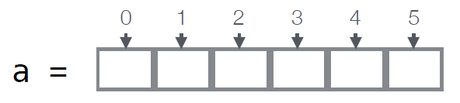 | 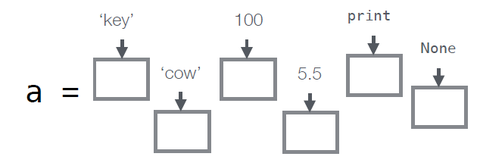 |

```python
d = {key1: value1, key2: value2, ...}
```

In [ ]:
# ✍️ Type along: a population lookup for Welsh cities

<details><summary>Code from class</summary>

```python
pop = {"Cardiff": 362400, "Swansea": 238500}   # ONS Census 2021, rounded
print(pop["Cardiff"])            # look up by key
pop["Newport"] = 159600          # add a new key
pop["Cardiff"] = 362800          # an existing key: the value is replaced
print(pop, len(pop))
print("Swansea" in pop)          # `in` checks the keys
```

</details>

Keys are **unique**: assigning to an existing key replaces its value. Since Python 3.7 a dictionary remembers the order in which keys were **inserted**, but there are still no positions: `d[0]` looks up the *key* `0`.

**Before we run this:** what happens when we look up a city that isn't there?

In [ ]:
# ⚠️ This cell raises an error on purpose
pop = {"Cardiff": 362400, "Swansea": 238500}
pop["Bristol"]

A `KeyError`. Two safe alternatives: check first with `in`, or use **`get(key, default)`**, which returns the default instead of failing.

| Method | Returns / does |
|---|---|
| `d.get(k, default)` | the value for `k`, or `default` (or `None`) if `k` is missing |
| `d.update(other)` | adds (or replaces) every key–value pair from `other` |
| `d.pop(k)` | removes `k` and returns its value |
| `d.keys()`, `d.values()`, `d.items()` | the keys, the values, the `(key, value)` pairs |
| `del d[k]`, `d.clear()` | remove one item / every item |

In [ ]:
pop = {"Cardiff": 362400, "Swansea": 238500}
print(pop.get("Cardiff"), pop.get("Bristol"), pop.get("Bristol", 0))
pop.update({"Newport": 159600, "Wrexham": 44800})
print(pop.pop("Swansea"), pop)
print(list(pop.items()))

**Predict:** `min()` and `max()` work on dictionaries. With `d = {"One": 1, "Two": 2, "Five": 5}`, what are `min(d)` and `min(d.values())`?

In [ ]:
d = {"One": 1, "Two": 2, "Five": 5}
print(min(d), max(d))
print(min(d.values()), max(d.values()))

On a dictionary, `min`/`max` (and `in`, and `len`) work on the **keys**: `"Five"` comes first alphabetically. Use `.values()` to work on the values. In the same way, `'ten' in d` checks the keys, and `'ten' in d.values()` checks the values.

### Which objects can be keys?

Dictionary look-ups are fast because each key is turned into a number by a **hash function**. The number tells Python where to find the value.

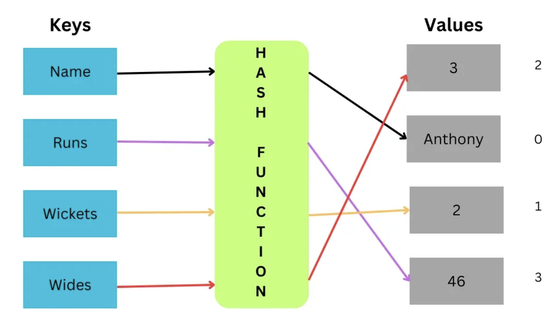

* `hash(obj)` returns that number, if the object has one.
* Immutable built-in objects (numbers, `bool`, `str`, tuples of these) are **hashable**.
* Lists and dictionaries are mutable, so they are **not** hashable and cannot be keys. (If a key could change, its hash would change and the value would be lost.)

**Quick check:** which of these can be a dictionary key? `"CF10"` · `42` · `(51.48, -3.18)` · `["CF10", "CF11"]`

<details><summary>Answer</summary>

The first three. The list can't: `hash(["CF10", "CF11"])` raises `TypeError: unhashable type: 'list'`. A tuple of coordinates is a handy key, for example to look up the name of a place.

</details>

In [ ]:
# ⚠️ This cell raises an error on purpose
print(hash(10), hash("Cardiff"), hash((51.48, -3.18)))
hash(["CF10", "CF11"])

**Your turn:** build a dictionary `cities` with Cardiff (362400), Swansea (238500) and Newport (159600). Add `"Bangor"` with population `18300`. Then print the population of `"Wrexham"` **without** a `KeyError` (print `unknown` instead), and print the total population of the cities in your dictionary.

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
cities = {"Cardiff": 362400, "Swansea": 238500, "Newport": 159600}
cities["Bangor"] = 18300                 # or cities.update({"Bangor": 18300})
print(cities.get("Wrexham", "unknown"))
print(sum(cities.values()))              # sum() adds up any sequence of numbers
```

</details>

### Putting it together: which collection?

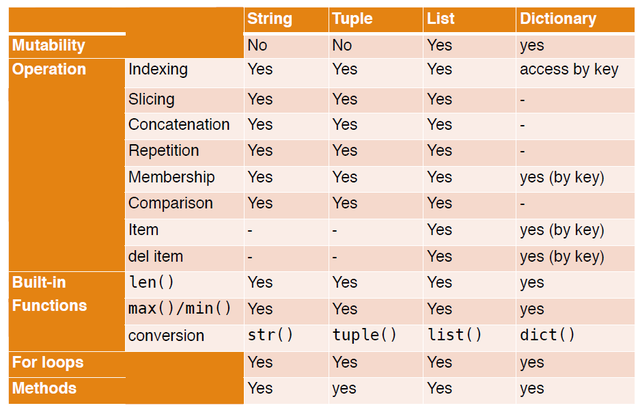

The *For loops* row is next week. And watch the brackets:

| | Looks like | Ordered by | Changeable? |
|---|---|---|---|
| tuple | `("one", "two", 3)` | position | no |
| list | `["one", "two", 3]` | position | yes |
| dict | `{"one": 1, "two": 2}` | key | yes |

**Discuss:** which collection would you use for each, and why?
1. The seven daily temperatures of one week.
2. The latitude and longitude of a weather station.
3. The population of every Welsh local authority, looked up by name.

<details><summary>Answer</summary>

1. A **list**: ordered by day, and you may append next week's values.
2. A **tuple**: two values that belong together and should not change (and a tuple can be a dictionary key).
3. A **dictionary**: you look values up by name, not by position.

</details>

### Takeaways: dictionaries

* A dictionary maps **unique, hashable keys** to values: `d[key]`, `d.get(key, default)`.
* `in`, `len`, `min` and `max` work on the **keys**; use `.values()` or `.items()` for the rest.
* Dictionaries are mutable: add with `d[k] = v` or `update`, remove with `pop` or `del`.
* Lists and dictionaries can't be keys; strings, numbers and tuples can.

## Transition to the lab

**You now know** how to store many values in tuples, lists and dictionaries, how to change lists safely, and how to look values up by key.

**The lab** (`W02_lab_student.ipynb`, one hour) practises exactly these skills on a week of Cardiff weather and a population lookup: summarising a list with built-in functions, slicing out the weekend, the copy trap, and a dictionary of cities. There are no loops in the lab: everything can be done with what you learnt today.

## Week 2 takeaways

* **Tuples** and **lists** are sequences: index from 0, slice with the end excluded, `len`/`min`/`max`, `in`, `+`, `*`.
* Tuples (and strings) are **immutable**; lists are **mutable**.
* `b = a` shares one list; `a.copy()` makes a new one.
* `.sort()` changes a list and returns `None`; `sorted()` returns a new list.
* **Dictionaries** look values up by **key**; `get()` avoids a `KeyError`; keys must be hashable.

## Where next

**Week 3 · Programme flow.** So far every line runs exactly once, top to bottom. Next week your programs make **decisions** (`if`/`elif`/`else`) and **repeat** work (`while`, `for`). A `for` loop over a list or a dictionary is where today's collections really pay off.

Before next week: reopen this notebook, run it top to bottom, and finish any *Your turn* you skipped.

## Optional: explore after class

**Sets.** A `set` holds **unique** items, with no order and no indexing. Membership tests are very fast. Careful: `{}` on its own is an empty **dictionary**; an empty set is `set()`.

In [ ]:
s = {3, 1, 3, 2}
print(s, 2 in s)
print(set("hello"))           # the order may vary
print(type({}), type(set()))

**Converting between collections.** `str()`, `list()` and `tuple()` convert between sequence types, and `dict()` builds a dictionary from pairs:

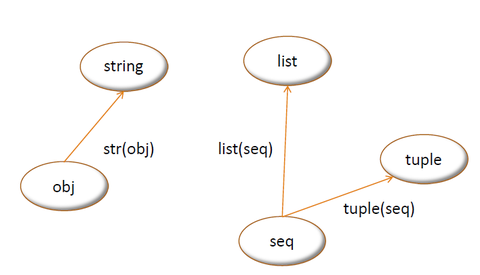

In [ ]:
print(str([1, 2, 3]), list("Hello"), tuple([1, 2, 3]))
print(dict([("hello", "hola"), (100000, "large number")]))

**Getting help.** `help(list.extend)` or `help(dict.get)` prints the documentation of a method. In Colab you can also type `basket.` and wait to see the list of methods.